# Modelagem de bateria Li-ion: Rint e Thevenin 1RC com dados CALCE

**PSI3591 – Trabalho de Conclusão de Curso** · Etapa **E3** (modelagem) do plano de trabalho

Este notebook reúne, em ordem de dependência:

1. **Biblioteca de modelos** (Rint, Thevenin 1RC, curva OCV–SoC, contagem de Coulomb, métricas e identificação de parâmetros);
2. **Testes automáticos** com dados sintéticos e soluções analíticas;
3. **Importador do dataset CALCE** (célula A123 LiFePO4): ensaio de OCV a baixa corrente e perfis dinâmicos DST, US06 e FUDS;
4. **Pipeline experimental**: identificar no **DST** e validar no **FUDS** (e no US06), como o próprio CALCE descreve para esta célula.

### Como usar
Execute as células em ordem (*Ambiente de execução → Executar tudo*). As partes 1 a 3 não precisam de dados e terminam com testes. A parte 4 precisa dos arquivos do CALCE (instruções na seção 4.1).

### O que foi verificado e o que não foi
* **Verificado** na página oficial do CALCE: a célula A123 é LiFePO4 com capacidade nominal de 1100 mAh; existe um arquivo por temperatura com os três perfis (DST, US06, FUDS) lado a lado, da esquerda para a direita; existem arquivos de OCV a baixa corrente por temperatura; o DST serve para identificar e o FUDS para validar.
* **Não verificado** (não consegui baixar os arquivos): nomes exatos de abas e colunas, unidade e sinal da corrente, taxa de amostragem e SoC inicial dos perfis. Por isso o importador **detecta colunas por padrão de nome**, **detecta o sinal da corrente fisicamente** e imprime uma **auditoria** que vocês devem conferir e registrar na especificação (D3).
* Os testes do importador usam planilhas sintéticas no layout descrito acima. Eles provam que a lógica funciona, **não** que o layout real é idêntico.

---
# Parte 1 – Biblioteca de modelos

## 1.1 Configuração e convenções

Estas convenções valem para **todo** o código e devem constar na especificação experimental (D3):

| Item | Convenção |
|---|---|
| Corrente | $I > 0$ na **descarga**, $I < 0$ na **carga** (Plett 2004; Xing et al. 2014) |
| SoC | fração entre 0 e 1 |
| Unidades | tempo em s, tensão em V, corrente em A, capacidade em Ah, resistência em ohm |
| Amostragem | uniforme, com período $\Delta t$ |
| Alinhamento | $x[k+1] = f(x[k], i[k])$; a tensão em $k$ usa $i[k]$ e $x[k]$ |

A discretização assume **corrente constante entre amostras** (Plett 2004, Parte 2).

In [1]:
import glob
import json
import os
import re
import sys
import tempfile
import warnings
import zipfile
from dataclasses import asdict, dataclass, field
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from scipy.optimize import least_squares
from scipy.signal import cont2discrete, lfilter

print("numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | scipy 1.16.3 | pandas 2.2.3


## 1.2 Utilidades de validação e de dados

Os modelos assumem vetores 1-D sem NaN e amostragem uniforme. As funções abaixo garantem isso e tratam três problemas típicos de dados reais:

* **tempos repetidos ou fora de ordem** (`clean_time`);
* **amostragem não uniforme** (`resample_uniform`), com corrente mantida constante entre amostras (*zero-order hold*), coerente com a discretização, e tensão por interpolação linear;
* **sinal da corrente desconhecido** (`detect_current_sign`). Quando a corrente degrau muda de $\Delta I$, a queda ôhmica faz a tensão mudar instantaneamente de $\Delta V = -R_0\,\Delta I$ (convenção descarga positiva). Logo, a soma de $\Delta I\cdot\Delta V$ nos grandes degraus é **negativa** se a convenção já for descarga positiva e **positiva** caso contrário. Isso dá um teste físico do sinal, sem depender de documentação do arquivo.

In [2]:
# Converte para vetor 1-D de floats e recusa vetores vazios ou com NaN/Inf
def as_1d(x, name):
    arr = np.asarray(x, dtype=float)
    if arr.ndim != 1 or arr.size == 0:
        raise ValueError(f"'{name}' deve ser um vetor 1-D não vazio.")
    if not np.all(np.isfinite(arr)):
        raise ValueError(f"'{name}' contém NaN ou Inf.")
    return arr


# Garante que todos os vetores informados têm o mesmo tamanho
def same_length(**arrays):
    tamanhos = {k: len(v) for k, v in arrays.items()}
    if len(set(tamanhos.values())) != 1:
        raise ValueError(f"Vetores com tamanhos diferentes: {tamanhos}")


# Período de amostragem dt [s] de um vetor de tempo uniforme. Levanta ValueError
# se o tempo não for crescente ou não for uniforme (nesse caso, reamostre antes).
def sampling_period(t, rtol=1e-3):
    t = as_1d(t, "t")
    if t.size < 2:
        raise ValueError("São necessárias ao menos 2 amostras.")
    d = np.diff(t)
    if np.any(d <= 0):
        raise ValueError("O vetor de tempo deve ser estritamente crescente.")
    dt = float(np.median(d))
    if np.max(np.abs(d - dt)) > rtol * dt:
        raise ValueError(
            f"Amostragem não uniforme (desvio > {rtol:.1e} do dt mediano = {dt:g} s). "
            "Reamostre os dados."
        )
    return dt


# Ordena pelo tempo e remove instantes repetidos (mantém o primeiro). Aplica a mesma
# seleção a todos os vetores extras. Retorna (t, v1, v2, ...).
def clean_time(t, *arrays):
    t = as_1d(t, "t")
    extras = [as_1d(a, f"vetor {k}") for k, a in enumerate(arrays)]
    same_length(t=t, **{f"vetor{k}": a for k, a in enumerate(extras)})
    t_unico, idx = np.unique(t, return_index=True)
    return (t_unico, *[a[idx] for a in extras])


# Reamostra em grade uniforme de passo dt. A corrente é mantida constante entre amostras
# (zero-order hold) e a tensão é interpolada linearmente.
def resample_uniform(t, i, v, dt):
    t, i, v = as_1d(t, "t"), as_1d(i, "i"), as_1d(v, "v")
    t_novo = np.arange(t[0], t[-1] + 1e-9, dt)
    idx = np.searchsorted(t, t_novo, side="right") - 1
    return t_novo, i[idx], np.interp(t_novo, t, v)


# Detecta se a corrente já está em "descarga positiva". Retorna (fator, correlação), onde
# fator = +1 (manter) ou -1 (inverter o sinal). A correlação serve como indicador de confiança.
def detect_current_sign(i, v, frac=0.2):
    i, v = as_1d(i, "i"), as_1d(v, "v")
    di, dv = np.diff(i), np.diff(v)
    limite = frac * np.max(np.abs(di))
    if limite == 0:
        raise ValueError("Corrente constante: não é possível detectar o sinal.")
    m = np.abs(di) >= limite
    soma = float(np.sum(di[m] * dv[m]))
    corr = float(np.corrcoef(di[m], dv[m])[0, 1]) if m.sum() > 2 else float("nan")
    fator = 1.0 if soma < 0 else -1.0
    if not (abs(corr) >= 0.5):
        warnings.warn(f"Detecção de sinal pouco confiável (correlação {corr:.2f}). "
                      "Confira a convenção da corrente manualmente.")
    return fator, corr

## 1.3 Curva OCV–SoC

A tensão de circuito aberto (OCV) é tratada como **função de SoC**, em tabela com **interpolação linear**, como em Plett (2004, Parte 2: tabela de 200 pontos). Para dados de baixa corrente, a curva é a **média das curvas de carga e descarga** (Plett 2004; Xing et al. 2014), o que cancela em primeira ordem a queda ôhmica; a histerese é ignorada, como nesses trabalhos.

Pontos de atenção:

* `slope()` fornece $d\,\mathrm{OCV}/d\,\mathrm{SoC}$ para a Jacobiana de observação do EKF (etapa E4).
* `inverse()` estima SoC a partir de uma tensão em repouso. Em células **LiFePO4 a curva tem um platô muito plano** (Xing et al. 2014 reportam inclinação da ordem de 1,4 mV por ponto percentual de SoC na faixa intermediária), então a inversão é **ambígua nessa região**. Use-a apenas como estimativa grosseira e confira com a descrição do ensaio.
* Fora do intervalo da tabela o valor é mantido constante. Se o SoC simulado sair de [0, 1], isso indica erro de SoC inicial, de capacidade ou de sinal.

In [3]:
class OCVTable:
    # soc e ocv: vetores do mesmo tamanho (SoC em fração).
    # monotonic='raise' recusa curvas não crescentes; 'fix' aplica um máximo acumulado
    # (útil para dados ruidosos, mas registre que a correção foi feita).
    def __init__(self, soc, ocv, monotonic="raise"):
        soc = as_1d(soc, "soc")
        ocv = as_1d(ocv, "ocv")
        same_length(soc=soc, ocv=ocv)
        ordem = np.argsort(soc)
        soc, ocv = soc[ordem], ocv[ordem]
        if np.any(np.diff(soc) <= 0):
            raise ValueError("Valores de SoC devem ser distintos.")
        if np.any(np.diff(ocv) < 0):
            if monotonic == "fix":
                ocv = np.maximum.accumulate(ocv)
            else:
                raise ValueError("OCV não é monotônica em SoC. Suavize os dados ou use "
                                 "monotonic='fix' (e documente a correção).")
        self.soc = soc
        self.ocv = ocv

    def __call__(self, soc):
        return np.interp(np.asarray(soc, dtype=float), self.soc, self.ocv)

    # Derivada dOCV/dSoC [V por unidade de SoC] da curva linear por partes
    def slope(self, soc):
        z = np.asarray(soc, dtype=float)
        idx = np.clip(np.searchsorted(self.soc, z, side="right") - 1, 0, len(self.soc) - 2)
        return (self.ocv[idx + 1] - self.ocv[idx]) / (self.soc[idx + 1] - self.soc[idx])

    # SoC correspondente a uma tensão em repouso. Ambígua em platôs (ver texto acima).
    def inverse(self, v):
        ocv_estrito = self.ocv + 1e-12 * np.arange(len(self.ocv))
        return np.interp(np.asarray(v, dtype=float), ocv_estrito, self.soc)

    # Curva OCV como média das curvas de carga e descarga a baixa corrente, reamostrada
    # em n_points pontos na faixa de SoC comum às duas curvas.
    @classmethod
    def from_charge_discharge(cls, soc_chg, v_chg, soc_dis, v_dis, n_points=200):
        sc, vc = as_1d(soc_chg, "soc_chg"), as_1d(v_chg, "v_chg")
        sd, vd = as_1d(soc_dis, "soc_dis"), as_1d(v_dis, "v_dis")
        same_length(soc_chg=sc, v_chg=vc)
        same_length(soc_dis=sd, v_dis=vd)
        oc, od = np.argsort(sc), np.argsort(sd)
        sc, vc, sd, vd = sc[oc], vc[oc], sd[od], vd[od]
        lo, hi = max(sc.min(), sd.min()), min(sc.max(), sd.max())
        if hi <= lo:
            raise ValueError("Curvas de carga e descarga sem faixa de SoC comum.")
        grade = np.linspace(lo, hi, n_points)
        ocv = 0.5 * (np.interp(grade, sc, vc) + np.interp(grade, sd, vd))
        return cls(grade, ocv, monotonic="fix")

    def to_dict(self):
        return {"soc": self.soc.tolist(), "ocv": self.ocv.tolist()}

    @classmethod
    def from_dict(cls, d):
        return cls(d["soc"], d["ocv"])

## 1.4 SoC por contagem de Coulomb

Recorrência de Plett (2004, Parte 2, eq. 4), com corrente positiva na descarga:

$$z_{k+1} = z_k - \frac{\eta_i\,\Delta t}{3600\,Q}\, i_k, \qquad \eta_i = \begin{cases}1 & i_k \ge 0 \text{ (descarga)}\\ \eta \le 1 & i_k < 0 \text{ (carga)}\end{cases}$$

Aqui o SoC é usado como **referência** para identificar o modelo de tensão (como em Xing et al. 2014). O vetor de saída tem o mesmo tamanho de `i`, com `soc[0] = soc0`.

In [4]:
def integrate_soc(i, dt, soc0, capacity_ah, eta=1.0):
    i = as_1d(i, "i")
    if capacity_ah <= 0 or dt <= 0:
        raise ValueError("capacity_ah e dt devem ser positivos.")
    eta_i = np.where(i < 0, eta, 1.0)
    dz = eta_i * i * dt / (3600.0 * capacity_ah)
    soc = np.empty_like(i)
    soc[0] = soc0
    soc[1:] = soc0 - np.cumsum(dz[:-1])
    return soc

## 1.5 Modelo Rint

$$V_k = \mathrm{OCV}(z_k) - R_0\, i_k$$

É o baseline estrutural (Hu et al. 2012, modelo 2): uma fonte dependente de SoC com resistência série e **sem dinâmica** (não representa relaxação). Como em Hu et al., aceita-se $R_0$ distinto na carga (`r0_charge`); se for `None`, usa-se o mesmo valor.

In [5]:
@dataclass
class SimResult:
    v: np.ndarray
    soc: np.ndarray
    v1: Optional[np.ndarray] = None


@dataclass(frozen=True)
class RintParams:
    r0: float
    r0_charge: Optional[float] = None

    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_dict(cls, d):
        return cls(**d)


class RintModel:
    name = "rint"

    def __init__(self, params, ocv):
        self.params = params
        self.ocv = ocv

    # R0 efetivo em cada amostra (descarga: r0; carga: r0_charge, se definido)
    def _r0(self, i):
        r_chg = self.params.r0 if self.params.r0_charge is None else self.params.r0_charge
        return np.where(i < 0, r_chg, self.params.r0)

    # Tensão prevista dado um SoC (por exemplo, o de referência). dt e v1_0 são ignorados:
    # existem apenas para manter a mesma interface do modelo 1RC.
    def voltage(self, i, soc, dt=None, v1_0=0.0):
        i = as_1d(i, "i")
        soc = as_1d(soc, "soc")
        same_length(i=i, soc=soc)
        return self.ocv(soc) - self._r0(i) * i

    def simulate(self, i, dt, soc0, capacity_ah, eta=1.0):
        soc = integrate_soc(i, dt, soc0, capacity_ah, eta)
        return SimResult(v=self.voltage(i, soc), soc=soc)

## 1.6 Modelo Thevenin 1RC

Acrescenta ao Rint um ramo RC que representa polarização e relaxação (Hu et al. 2012, modelo 7), com $\tau_1 = R_1 C_1$:

$$U_{1,k+1} = e^{-\Delta t/\tau_1}\,U_{1,k} + R_1\left(1 - e^{-\Delta t/\tau_1}\right) i_k, \qquad V_k = \mathrm{OCV}(z_k) - R_0\, i_k - U_{1,k}$$

**Discretização.** A forma acima é *exata* (zero-order hold) para qualquer $\Delta t$ se a corrente for constante entre amostras. O Euler direto, $a = 1 - \Delta t/\tau_1$ e $b = R_1 \Delta t/\tau_1$, só é adequado se $\Delta t \ll \tau_1$; ele está disponível (`method="euler"`) para estudar esse erro.

**Implementação eficiente.** Com parâmetros fixos, $U_1$ é a saída de um filtro IIR de primeira ordem excitado por $i$, então `scipy.signal.lfilter` o calcula de forma vetorizada, sem laço em Python. Com $b_0 = 0$, a saída em $k=0$ é o estado inicial `zi`, o que fixa $U_{1,0}$ = `v1_0`. Isso acelera bastante a otimização da seção 1.8, e os testes comparam o resultado com a recursão explícita.

In [6]:
# Coeficientes (a, b) de U1[k+1] = a*U1[k] + b*i[k]
def rc_discretization(r1, tau1, dt, method="exact"):
    if tau1 <= 0 or dt <= 0:
        raise ValueError("tau1 e dt devem ser positivos.")
    if method == "exact":
        a = float(np.exp(-dt / tau1))
        return a, r1 * (1.0 - a)
    if method == "euler":
        return 1.0 - dt / tau1, r1 * dt / tau1
    raise ValueError("method deve ser 'exact' ou 'euler'.")


# U1[0] = v1_0 e U1[k+1] = a*U1[k] + b*i[k], via filtro IIR
def _rc_voltage(i, a, b, v1_0):
    y, _ = lfilter([0.0, b], [1.0, -a], i, zi=[v1_0])
    return y


@dataclass(frozen=True)
class TheveninParams:
    r0: float
    r1: float
    tau1: float

    # C1 = tau1 / R1 [F]
    @property
    def c1(self):
        return self.tau1 / self.r1

    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_dict(cls, d):
        return cls(**d)


# Parâmetros constantes (versão inicial prevista no plano: constantes ou tabelados,
# desde que a decisão seja testada e documentada)
class Thevenin1RC:
    name = "thevenin_1rc"

    def __init__(self, params, ocv, discretization="exact"):
        self.params = params
        self.ocv = ocv
        self.discretization = discretization

    # Tensão U1[k] do ramo RC para uma sequência de corrente
    def polarization(self, i, dt, v1_0=0.0):
        i = as_1d(i, "i")
        a, b = rc_discretization(self.params.r1, self.params.tau1, dt, self.discretization)
        return _rc_voltage(i, a, b, v1_0)

    # V[k] = OCV(z[k]) - R0*i[k] - U1[k], dado um SoC
    def voltage(self, i, soc, dt, v1_0=0.0):
        i = as_1d(i, "i")
        soc = as_1d(soc, "soc")
        same_length(i=i, soc=soc)
        u1 = self.polarization(i, dt, v1_0)
        return self.ocv(soc) - self.params.r0 * i - u1

    def simulate(self, i, dt, soc0, capacity_ah, eta=1.0, v1_0=0.0):
        soc = integrate_soc(i, dt, soc0, capacity_ah, eta)
        u1 = self.polarization(i, dt, v1_0)
        v = self.ocv(soc) - self.params.r0 * np.asarray(i, float) - u1
        return SimResult(v=v, soc=soc, v1=u1)

## 1.7 Métricas

Seguem as definições de Xing et al. (2014, eqs. 3 e 4) e a seção 20 do plano. O sinal do erro é `referência − estimativa`.

* **MAE** = média de $|e_k|$ · **RMSE** = $\sqrt{\text{média de } e_k^2}$ · **erro máximo** = $\max|e_k|$.
* `evaluate_voltage` usa o **SoC de referência** (e não o simulado), isolando o erro do modelo de tensão do erro de Coulomb. Devolve também o **resíduo no tempo**, pois o plano pede analisar a estrutura temporal do erro e não só a média.

In [7]:
def _err(reference, estimate):
    r, e = as_1d(reference, "reference"), as_1d(estimate, "estimate")
    same_length(reference=r, estimate=e)
    return r - e


def mae(reference, estimate):
    return float(np.mean(np.abs(_err(reference, estimate))))


def rmse(reference, estimate):
    return float(np.sqrt(np.mean(_err(reference, estimate) ** 2)))


def max_abs_error(reference, estimate):
    return float(np.max(np.abs(_err(reference, estimate))))


def error_summary(reference, estimate):
    return {"mae": mae(reference, estimate), "rmse": rmse(reference, estimate),
            "max_abs": max_abs_error(reference, estimate)}


# Avalia um modelo (Rint ou 1RC) contra a tensão medida. skip descarta as primeiras
# amostras (transitório da condição inicial de U1). Retorna métricas e o resíduo v - v_prev.
def evaluate_voltage(model, i, v, soc, dt, v1_0=0.0, skip=0):
    v = as_1d(v, "v")
    v_pred = model.voltage(i, soc, dt, v1_0)
    s = slice(skip, None)
    out = error_summary(v[s], v_pred[s])
    out["residual"] = v - v_pred
    return out

## 1.8 Identificação de parâmetros

### Rint
Como $V - \mathrm{OCV}(z) = -R_0\, i$, o problema é **linear** e tem solução fechada por mínimos quadrados (Plett 2004, Parte 2; Xing et al. 2014): $\theta = (H^T H)^{-1} H^T y$ com $y = v - \mathrm{OCV}(z)$. Com `directional=True` estimam-se $R_0$ de descarga e de carga separadamente (R0⁺ e R0⁻ em Hu et al. 2012).

### Thevenin 1RC
O problema é **não linear** em $(R_0, R_1, \tau_1)$. Usa-se `scipy.optimize.least_squares` (método *trust region reflective*, com limites nos parâmetros) para minimizar o erro de tensão. Hu et al. (2012) recorreram a otimização global por causa de mínimos locais; aqui se usa ***multi-start* em $\tau_1$** e guarda-se a melhor solução. O chute inicial de $R_0$ vem do Rint.

**Atenção aos limites.** Os limites padrão (R0 e R1 em [1e-4; 0,5] ohm, $\tau_1$ em [$\Delta t$; 2000] s) são genéricos. Ajuste-os à célula e **registre-os**. Parâmetro colado em um limite é sinal de problema de identificabilidade ou de modelo (o plano trata parâmetros fisicamente implausíveis assim), e o código emite aviso.

O campo `param_std` vem da Jacobiana no ótimo e supõe resíduos independentes. Como resíduos de modelos de circuito equivalente são autocorrelacionados, ele é **otimista**: use só como indicador relativo de identificabilidade.

In [8]:
@dataclass
class FitResult:
    params: object
    rmse_v: float
    mae_v: float
    n_samples: int
    success: bool = True
    message: str = ""
    at_bounds: list = field(default_factory=list)
    param_std: Optional[dict] = None
    start_costs: Optional[list] = None


def fit_rint(i, v, soc, ocv, directional=False):
    i, v, soc = as_1d(i, "i"), as_1d(v, "v"), as_1d(soc, "soc")
    same_length(i=i, v=v, soc=soc)
    y = v - ocv(soc)
    if directional:
        colunas = [np.where(i > 0, i, 0.0), np.where(i < 0, i, 0.0)]
        if not (np.any(colunas[0] != 0) and np.any(colunas[1] != 0)):
            raise ValueError("directional=True exige amostras de carga e de descarga.")
        H = -np.column_stack(colunas)
    else:
        H = -i[:, None]
    theta, *_ = np.linalg.lstsq(H, y, rcond=None)
    if np.any(theta <= 0):
        warnings.warn("R0 identificado não positivo: verifique a convenção de sinal da "
                      "corrente, a curva OCV e o SoC.")
    params = RintParams(float(theta[0]), float(theta[1]) if directional else None)
    pred = RintModel(params, ocv).voltage(i, soc)
    return FitResult(params=params, rmse_v=rmse(v, pred), mae_v=mae(v, pred), n_samples=len(i))


def fit_thevenin_1rc(i, v, soc, ocv, dt, bounds=None, tau_starts=None, v1_0=0.0,
                     discretization="exact"):
    i, v, soc = as_1d(i, "i"), as_1d(v, "v"), as_1d(soc, "soc")
    same_length(i=i, v=v, soc=soc)
    if dt <= 0:
        raise ValueError("dt deve ser positivo.")

    # limites [r0, r1, tau1]
    if bounds is None:
        lo = np.array([1e-4, 1e-4, dt])
        hi = np.array([0.5, 0.5, 2000.0])
    else:
        lo, hi = (np.asarray(b, float) for b in bounds)
        if lo.shape != (3,) or hi.shape != (3,) or np.any(lo >= hi):
            raise ValueError("bounds deve ser (lo, hi) com 3 valores [r0, r1, tau1] e lo < hi.")
    if tau_starts is None:
        tau_starts = np.geomspace(max(10 * dt, lo[2]), min(1000.0, hi[2]), 6)

    ocv_v = ocv(soc)

    def predict(theta):
        r0, r1, tau1 = theta
        a, b = rc_discretization(r1, tau1, dt, discretization)
        return ocv_v - r0 * i - _rc_voltage(i, a, b, v1_0)

    def resid(theta):
        return v - predict(theta)

    # chute inicial de R0 vindo do Rint (mesma convenção de sinal)
    r0_ini = fit_rint(i, v, soc, ocv).params.r0 if np.any(i != 0) else lo[0]
    margem = 1e-6 * (hi - lo)

    melhor, custos = None, []
    for tau0 in np.atleast_1d(tau_starts):
        x0 = np.clip([max(0.5 * r0_ini, lo[0]), max(0.5 * r0_ini, lo[1]), tau0],
                     lo + margem, hi - margem)
        try:
            sol = least_squares(resid, x0, bounds=(lo, hi), method="trf", x_scale="jac")
        except ValueError as exc:
            custos.append(float("nan"))
            warnings.warn(f"Início tau0={tau0:g} s falhou: {exc}")
            continue
        custos.append(float(sol.cost))
        if melhor is None or sol.cost < melhor.cost:
            melhor = sol
    if melhor is None:
        raise RuntimeError("Todas as inicializações falharam.")

    params = TheveninParams(float(melhor.x[0]), float(melhor.x[1]), float(melhor.x[2]))
    pred = predict(melhor.x)

    # parâmetros colados em algum limite (tolerância de 0,1% da largura do intervalo)
    nomes = ["r0", "r1", "tau1"]
    tol = 1e-3 * (hi - lo)
    colados = [n for n, x, l, h, t in zip(nomes, melhor.x, lo, hi, tol)
               if (x - l) < t or (h - x) < t]
    if colados:
        warnings.warn(f"Parâmetros nos limites: {colados}. Revise limites, dados de "
                      "excitação ou estrutura do modelo.")

    # incerteza aproximada (ver texto acima)
    desvio = None
    gl = len(i) - 3
    if gl > 0:
        try:
            s2 = 2.0 * melhor.cost / gl
            cov = s2 * np.linalg.pinv(melhor.jac.T @ melhor.jac)
            desvio = dict(zip(nomes, np.sqrt(np.diag(cov)).tolist()))
        except np.linalg.LinAlgError:
            desvio = None
    return FitResult(params=params, rmse_v=rmse(v, pred), mae_v=mae(v, pred), n_samples=len(i),
                     success=bool(melhor.success), message=str(melhor.message),
                     at_bounds=colados, param_std=desvio, start_costs=custos)

## 1.9 Persistência de parâmetros

Os parâmetros identificados são gravados em JSON junto com metadados do ensaio (perfil, temperatura, célula, limites, data), para que qualquer resultado do relatório possa ser reproduzido.

In [9]:
def save_params(path, model_name, params, meta=None):
    with open(path, "w", encoding="utf-8") as f:
        json.dump({"model": model_name, "params": params.to_dict(), "meta": meta or {}},
                  f, indent=2, ensure_ascii=False)


def load_params(path):
    with open(path, encoding="utf-8") as f:
        d = json.load(f)
    classe = {"rint": RintParams, "thevenin_1rc": TheveninParams}[d["model"]]
    return classe.from_dict(d["params"]), d.get("meta", {})

---
# Parte 2 – Importador do dataset CALCE (célula A123 LiFePO4)

## 2.1 O que a página do CALCE informa

* Capacidade nominal de **1100 mAh**, química **LiFePO4**.
* **OCV a baixa corrente**: um arquivo por temperatura (de -10 a 50 °C), com descarga e carga lentas. A tensão média de carga e descarga aproxima a OCV.
* **Perfis dinâmicos**: um arquivo por temperatura com os **três perfis lado a lado** (DST, US06, FUDS, da esquerda para a direita). O DST serve para identificar parâmetros e o FUDS para validar.
* Nomes típicos dentro dos arquivos compactados: `A1-007-OCV(25)-...xlsx` e `A1-007-DST(25)-US06-FUDS-...xlsx`.

## 2.2 Decisões de projeto do importador

| Problema | Decisão |
|---|---|
| Nomes de abas e colunas não verificados | Colunas detectadas por **padrão de nome** (`time`, `current`, `voltage`, `temp`), com opção de **informar os nomes à mão** (`columns=`) |
| Três perfis na mesma aba | Colunas repetidas são associadas **na ordem da esquerda para a direita** a `("DST", "US06", "FUDS")`; o número de blocos precisa coincidir entre tempo, corrente e tensão |
| Sinal da corrente desconhecido | Detecção física do sinal (seção 1.2); também é possível forçar com `current_sign="as_is"` ou `"flip"` |
| Tempo irregular | Limpeza e reamostragem uniforme (corrente em *zero-order hold*) |
| Ensaio de OCV sem convenção de sinal conhecida | Os trechos lentos são classificados como **descarga** ou **carga** pela **tendência da tensão** (cai = descarga), sem depender do sinal da corrente |
| Capacidade de referência | Capacidade **medida** na descarga lenta do próprio ensaio de OCV, na mesma temperatura. O plano exige que a convenção de $Q_\mathrm{ref}$ seja explícita; esta é uma escolha que deve constar na D3 |

Cada função imprime ou devolve informações para **auditoria**. Registrem esses números na especificação experimental.

In [10]:
# ----- localização e leitura de arquivos -----

# Descompacta todos os .zip encontrados na pasta (cada um em uma subpasta com o seu nome)
def extract_all_zips(pasta):
    for z in glob.glob(os.path.join(pasta, "**", "*.zip"), recursive=True):
        destino = z[:-4]
        if not os.path.isdir(destino):
            with zipfile.ZipFile(z) as arq:
                arq.extractall(destino)
            print("Descompactado:", z)


# Procura o arquivo do ensaio pelo tipo ("ocv" ou "din") e pela temperatura em °C.
# Os padrões seguem os nomes descritos na página do CALCE, por exemplo
# "A1-007-OCV(25)-..." e "A1-007-DST(25)-US06-FUDS-...". Se houver mais de um arquivo
# (por exemplo, duas células), devolve erro listando as opções.
def locate_calce_file(pasta, tipo, temp_c):
    t = re.escape(str(temp_c))
    if tipo == "ocv":
        padroes = [rf"ocv\(?\s*{t}(?!\d)"]
    elif tipo == "din":
        padroes = [rf"dst\(?\s*{t}(?!\d).*us06.*fuds", rf"dst.*us06.*fuds.*-{t}(?!\d)"]
    else:
        raise ValueError("tipo deve ser 'ocv' ou 'din'.")
    arquivos = [f for f in glob.glob(os.path.join(pasta, "**", "*"), recursive=True)
                if os.path.isfile(f) and f.lower().endswith((".xlsx", ".xls", ".csv"))]
    for p in padroes:
        achados = [f for f in arquivos if re.search(p, os.path.basename(f), re.IGNORECASE)]
        if len(achados) == 1:
            return achados[0]
        if len(achados) > 1:
            raise ValueError("Mais de um arquivo corresponde; defina o caminho manualmente:\n"
                             + "\n".join(achados))
    raise FileNotFoundError(
        f"Nenhum arquivo '{tipo}' para {temp_c} °C em {pasta}. Arquivos vistos:\n"
        + "\n".join(os.path.basename(f) for f in arquivos))


# Mostra abas, dimensões e primeiras linhas para conferir o layout real do arquivo
def inspect_file(path, nrows=6):
    if path.lower().endswith(".csv"):
        df = pd.read_csv(path, header=None)
        print(f"CSV: {df.shape[0]} linhas x {df.shape[1]} colunas")
        display(df.head(nrows))
        return
    xl = pd.ExcelFile(path)
    print("Abas:", xl.sheet_names)
    for aba in xl.sheet_names:
        df = xl.parse(aba, header=None)
        print(f"\n--- aba '{aba}': {df.shape[0]} linhas x {df.shape[1]} colunas")
        display(df.head(nrows))


PADROES_COLUNAS = {
    "time": r"^(?!.*(step|date)).*time",
    "current": r"current",
    "voltage": r"voltage",
    "temperature": r"temp",
}


# Colunas de um tipo, na ordem da esquerda para a direita. override = {"time": [...], ...}
# permite informar os nomes à mão quando o padrão automático falhar.
def find_columns(df, kind, override=None):
    if override and kind in override:
        return list(override[kind])
    pad = re.compile(PADROES_COLUNAS[kind], re.IGNORECASE)
    return [c for c in df.columns if pad.search(str(c))]


# Lê o arquivo. Em Excel com várias abas, escolhe a de mais linhas que tenha colunas de
# tempo, corrente e tensão (ou use sheet=nome). header_row indica a linha do cabeçalho.
def read_table(path, sheet=None, header_row=0):
    if path.lower().endswith(".csv"):
        return pd.read_csv(path, header=header_row), "csv"
    tabelas = pd.read_excel(path, sheet_name=sheet, header=header_row)
    if isinstance(tabelas, pd.DataFrame):
        return tabelas, sheet
    candidatas = {n: d for n, d in tabelas.items()
                  if all(find_columns(d, k) for k in ("time", "current", "voltage"))}
    if not candidatas:
        raise ValueError("Nenhuma aba com colunas de tempo, corrente e tensão. Use "
                         "inspect_file() e informe sheet=, header_row= ou columns=.")
    nome = max(candidatas, key=lambda n: len(candidatas[n]))
    return candidatas[nome], nome


# ----- perfis dinâmicos -----

# Lê os blocos (DST, US06, FUDS) de um arquivo de perfis dinâmicos. Devolve
# {nome: {"t": ..., "i": ..., "v": ..., "temp": ... ou None}} com os dados brutos.
def load_dynamic_profiles(path, sheet=None, header_row=0,
                          profile_names=("DST", "US06", "FUDS"), columns=None):
    df, aba = read_table(path, sheet, header_row)
    cols = {k: find_columns(df, k, columns) for k in ("time", "current", "voltage")}
    contagem = {k: len(v) for k, v in cols.items()}
    if len(set(contagem.values())) != 1 or contagem["time"] == 0:
        raise ValueError(f"Contagem de colunas inconsistente {contagem}. Colunas do arquivo: "
                         f"{list(df.columns)}. Informe columns= manualmente.")
    n_blocos = contagem["time"]
    cols_temp = find_columns(df, "temperature", columns)
    blocos = {}
    for b in range(n_blocos):
        nome = profile_names[b] if n_blocos == len(profile_names) else f"bloco_{b + 1}"
        bruto = pd.DataFrame({
            "t": pd.to_numeric(df[cols["time"][b]], errors="coerce"),
            "i": pd.to_numeric(df[cols["current"][b]], errors="coerce"),
            "v": pd.to_numeric(df[cols["voltage"][b]], errors="coerce"),
        })
        valido = bruto.dropna()
        temp = None
        if len(cols_temp) == n_blocos:
            serie = pd.to_numeric(df[cols_temp[b]], errors="coerce").loc[valido.index]
            if serie.notna().all():
                temp = serie.to_numpy(float)
        blocos[nome] = {"t": valido["t"].to_numpy(float), "i": valido["i"].to_numpy(float),
                        "v": valido["v"].to_numpy(float), "temp": temp}
    print(f"Aba usada: {aba} | blocos encontrados: {list(blocos)}")
    return blocos


@dataclass
class Profile:
    name: str
    t: np.ndarray
    i: np.ndarray
    v: np.ndarray
    dt: float
    temp: Optional[np.ndarray] = None
    info: dict = field(default_factory=dict)


# Deixa um perfil pronto para os modelos: ordena e limpa o tempo, padroniza o sinal da
# corrente (descarga positiva), reamostra se a amostragem for irregular e zera o tempo.
# current_sign: "auto" (detecção física), "as_is" (manter) ou "flip" (inverter).
def prepare_profile(name, t, i, v, temp=None, current_sign="auto", dt=None, rtol=1e-3):
    extras = [i, v] + ([temp] if temp is not None else [])
    limpo = clean_time(t, *extras)
    t, i, v = limpo[0], limpo[1], limpo[2]
    temp = limpo[3] if temp is not None else None

    corr = float("nan")
    if current_sign == "auto":
        fator, corr = detect_current_sign(i, v)
    elif current_sign == "as_is":
        fator = 1.0
    elif current_sign == "flip":
        fator = -1.0
    else:
        raise ValueError("current_sign deve ser 'auto', 'as_is' ou 'flip'.")
    i = fator * i

    reamostrado = False
    try:
        dt_real = sampling_period(t, rtol)
    except ValueError:
        dt_real = float(dt) if dt is not None else float(np.median(np.diff(t)))
        t_novo, i, v = resample_uniform(t, i, v, dt_real)
        if temp is not None:
            temp = np.interp(t_novo, t, temp)
        t = t_novo
        reamostrado = True
    t = t - t[0]

    info = {"amostras": len(t), "dt_s": dt_real, "duracao_h": float(t[-1] / 3600.0),
            "fator_sinal": fator, "correlacao_sinal": corr, "reamostrado": reamostrado,
            "i_max_A": float(i.max()), "i_min_A": float(i.min()),
            "v_min_V": float(v.min()), "v_max_V": float(v.max())}
    return Profile(name=name, t=t, i=i, v=v, dt=dt_real, temp=temp, info=info)


# Tensão em repouso no início do ensaio: mediana das primeiras amostras com |I| pequena
def initial_rest_voltage(i, v, thr=0.01, max_samples=600):
    i, v = as_1d(i, "i"), as_1d(v, "v")
    repouso = np.abs(i[:max_samples]) < thr
    n = int(np.argmin(repouso)) if not repouso.all() else int(repouso.size)
    if n == 0:
        return float(v[0]), False
    return float(np.median(v[:n])), True


# ----- ensaio de OCV a baixa corrente -----

@dataclass
class OCVResult:
    table: OCVTable
    capacity_dis_ah: float
    capacity_chg_ah: float
    runs: pd.DataFrame
    soc_dis: np.ndarray
    v_dis: np.ndarray
    soc_chg: np.ndarray
    v_chg: np.ndarray


# Procura trechos contínuos de corrente lenta (thr <= |I| <= max_current_a) com o mesmo
# sinal. Cada trecho é classificado como DESCARGA ou CARGA pela tendência da tensão (cai
# = descarga), o que dispensa saber a convenção de sinal do arquivo. Escolhe o trecho de
# maior capacidade de cada tipo, calcula o SoC por Coulomb dentro do trecho (de 1 a 0 na
# descarga e de 0 a 1 na carga) e monta a curva pela média carga/descarga.
def load_ocv_lowcurrent(path, sheet=None, header_row=0, columns=None, thr=0.01,
                        max_current_a=0.2, min_len=100, n_points=200):
    df, aba = read_table(path, sheet, header_row)
    achou = {k: find_columns(df, k, columns) for k in ("time", "current", "voltage")}
    if not all(achou.values()):
        raise ValueError(f"Colunas não encontradas {achou}. Colunas: {list(df.columns)}")
    num = lambda c: pd.to_numeric(df[c[0]], errors="coerce")
    bruto = pd.DataFrame({"t": num(achou["time"]), "i": num(achou["current"]),
                          "v": num(achou["voltage"])}).dropna()
    t, i, v = clean_time(bruto["t"].to_numpy(float), bruto["i"].to_numpy(float),
                         bruto["v"].to_numpy(float))

    ativo = (np.abs(i) >= thr) & (np.abs(i) <= max_current_a)
    chave = np.where(ativo, np.sign(i), 0.0)
    limites = np.r_[0, np.flatnonzero(np.diff(chave) != 0) + 1, len(chave)]

    trechos = []
    for s, e in zip(limites[:-1], limites[1:]):
        if chave[s] == 0 or (e - s) < min_len:
            continue
        dt_seg = np.diff(t[s:e])
        q_acum = np.r_[0.0, np.cumsum(np.abs(i[s:e - 1]) * dt_seg)] / 3600.0
        trechos.append({"ini": s, "fim": e, "amostras": e - s,
                        "tipo": "descarga" if v[e - 1] < v[s] else "carga",
                        "corrente_media_A": float(np.mean(np.abs(i[s:e]))),
                        "duracao_h": float((t[e - 1] - t[s]) / 3600.0),
                        "capacidade_Ah": float(q_acum[-1]),
                        "v_ini": float(v[s]), "v_fim": float(v[e - 1]), "_q": q_acum})
    escolhidos = {}
    for tipo in ("descarga", "carga"):
        cand = [r for r in trechos if r["tipo"] == tipo]
        if not cand:
            raise ValueError(f"Nenhum trecho lento de {tipo} encontrado (thr={thr} A, "
                             f"max_current_a={max_current_a} A). Ajuste os parâmetros.")
        escolhidos[tipo] = max(cand, key=lambda r: r["capacidade_Ah"])

    d, c = escolhidos["descarga"], escolhidos["carga"]
    soc_dis = 1.0 - d["_q"] / d["capacidade_Ah"]
    soc_chg = c["_q"] / c["capacidade_Ah"]
    v_dis = v[d["ini"]:d["fim"]]
    v_chg = v[c["ini"]:c["fim"]]
    tabela = OCVTable.from_charge_discharge(soc_chg, v_chg, soc_dis, v_dis, n_points)

    resumo = pd.DataFrame([{k: val for k, val in r.items() if k != "_q"} for r in trechos])
    resumo["escolhido"] = [r is escolhidos[r["tipo"]] for r in trechos]
    print(f"Aba usada: {aba} | {len(t)} amostras | trechos lentos encontrados: {len(trechos)}")
    return OCVResult(tabela, d["capacidade_Ah"], c["capacidade_Ah"], resumo,
                     soc_dis, v_dis, soc_chg, v_chg)

## 2.3 Testes automáticos (modelos e importador)

Todos os testes usam dados sintéticos e soluções analíticas, então uma falha indica erro de implementação e não de dados. Os testes do importador geram planilhas `.xlsx` temporárias no layout descrito pelo CALCE (três blocos lado a lado, cabeçalhos repetidos, colunas separadoras, blocos de comprimentos diferentes, corrente com convenção "carga positiva" no estilo Arbin e amostragem irregular em um dos blocos).

Execute a célula e confira a linha final: todos devem passar.

In [11]:
# ----- utilidades de teste -----

def assert_close(a, b, rtol=1e-6, atol=0.0, msg=""):
    if not np.allclose(a, b, rtol=rtol, atol=atol):
        raise AssertionError(f"{msg} valores diferentes: {a} vs {b}")


def expect_error(funcao, exc=ValueError):
    try:
        funcao()
    except exc:
        return
    raise AssertionError(f"era esperado {exc.__name__}")


# OCV sintética monotônica, com platô (tipo LiFePO4)
def criar_ocv_sintetico():
    z = np.linspace(0, 1, 201)
    v = 3.2 + 0.15 * z - 0.2 * np.exp(-z / 0.05) + 0.25 * np.exp(-(1 - z) / 0.03)
    return OCVTable(z, v)


# Corrente de excitação: pulsos de descarga e carga com repousos (descarga positiva)
def criar_corrente(n=6000, seed=0):
    rng = np.random.default_rng(seed)
    i = np.zeros(n)
    k = 0
    while k < n:
        dur = int(rng.integers(30, 200))
        i[k:k + dur] = rng.choice([0.0, 0.5, 1.0, 2.0, -0.5, -1.0, 3.0])
        k += dur
    return i


# ----- testes dos modelos -----

def teste_periodo_de_amostragem():
    assert_close(sampling_period(np.arange(0, 10, 0.5)), 0.5)
    expect_error(lambda: sampling_period([0, 1, 2, 3.5, 4.5]))
    expect_error(lambda: sampling_period([0, 1, 1, 2]))


def teste_limpeza_e_reamostragem():
    t, i = clean_time([3, 1, 2, 2], [30, 10, 20, 99])
    assert_close(t, [1, 2, 3])
    assert_close(i, [10, 20, 30])
    t = np.array([0.0, 1.0, 2.5, 4.0])
    tn, in_, vn = resample_uniform(t, [1.0, 2.0, 3.0, 4.0], [10.0, 20.0, 30.0, 40.0], 1.0)
    assert_close(tn, [0, 1, 2, 3, 4])
    assert_close(in_, [1, 2, 2, 3, 4])          # corrente mantida (zero-order hold)
    assert_close(vn[2], 20 + (30 - 20) * (2 - 1) / 1.5)  # tensão interpolada linearmente


def teste_curva_ocv():
    t = OCVTable([0, 0.5, 1.0], [3.0, 3.2, 4.0])
    assert_close(t(0.25), 3.1)
    assert_close(t(-1), 3.0)
    assert_close(t.slope(0.25), 0.4)
    assert_close(t.slope(0.75), 1.6)
    assert_close(t.inverse(3.1), 0.25, atol=1e-9)
    expect_error(lambda: OCVTable([0, 0.5, 1], [3.0, 3.3, 3.2]))
    assert np.all(np.diff(OCVTable([0, 0.5, 1], [3.0, 3.3, 3.2], monotonic="fix").ocv) >= 0)


def teste_ocv_media_carga_descarga():
    z = np.linspace(0, 1, 50)
    t = OCVTable.from_charge_discharge(z, 3.0 + z + 0.01, z, 3.0 + z - 0.01)
    assert_close(t(z), 3.0 + z, atol=1e-9)


def teste_coulomb():
    soc = integrate_soc(np.full(3600, 2.0), 1.0, 1.0, 2.0)        # 1C durante 1 h
    assert soc[0] == 1.0
    assert_close(soc[-1], 1.0 / 3600.0, atol=1e-9)
    assert_close(integrate_soc([-1.0, -1.0, -1.0], 3600.0, 0.5, 1.0, eta=0.9)[1], 0.5 + 0.9)


def teste_discretizacao_igual_a_cont2discrete():
    r1, tau, dt = 0.03, 40.0, 1.0
    a, b = rc_discretization(r1, tau, dt, "exact")
    sistema = (np.array([[-1 / tau]]), np.array([[r1 / tau]]), np.array([[1.0]]), np.array([[0.0]]))
    Ad, Bd, *_ = cont2discrete(sistema, dt, method="zoh")
    assert_close(a, Ad[0, 0], rtol=1e-12)
    assert_close(b, Bd[0, 0], rtol=1e-12)
    ae, be = rc_discretization(0.03, 100.0, 0.01, "exact")
    au, bu = rc_discretization(0.03, 100.0, 0.01, "euler")
    assert_close(au, ae, atol=1e-7)
    assert_close(bu, be, rtol=1e-3)


def teste_rint():
    ocv = criar_ocv_sintetico()
    m = RintModel(RintParams(0.05, 0.08), ocv)
    v = m.voltage([1.0, -1.0], [0.5, 0.5])
    assert_close(v[0], ocv(0.5) - 0.05)
    assert_close(v[1], ocv(0.5) + 0.08)


def teste_identificacao_rint():
    ocv, i = criar_ocv_sintetico(), criar_corrente()
    soc = integrate_soc(i, 1.0, 0.95, 5.0)
    v = RintModel(RintParams(0.045), ocv).voltage(i, soc)
    assert_close(fit_rint(i, v, soc, ocv).params.r0, 0.045, rtol=1e-9)
    ruidoso = v + np.random.default_rng(1).normal(0, 1e-3, v.size)
    assert_close(fit_rint(i, ruidoso, soc, ocv).params.r0, 0.045, rtol=0.02)
    v2 = RintModel(RintParams(0.04, 0.07), ocv).voltage(i, soc)
    p = fit_rint(i, v2, soc, ocv, directional=True).params
    assert_close([p.r0, p.r0_charge], [0.04, 0.07], rtol=1e-9)


def teste_1rc_resposta_ao_degrau():
    r1, tau, dt, i0 = 0.03, 40.0, 1.0, 2.0
    m = Thevenin1RC(TheveninParams(0.04, r1, tau), criar_ocv_sintetico())
    u1 = m.polarization(np.full(300, i0), dt)
    esperado = r1 * i0 * (1 - np.exp(-np.arange(300) * dt / tau))     # U1[0] = 0
    assert_close(u1, esperado, atol=1e-12)
    rep = m.polarization(np.zeros(100), 1.0, v1_0=0.05)
    assert_close(rep[0], 0.05)
    assert_close(rep[50], 0.05 * np.exp(-50 / 40.0), rtol=1e-12)


def teste_1rc_igual_a_recursao_explicita():
    p = TheveninParams(0.04, 0.03, 35.0)
    ocv = criar_ocv_sintetico()
    i = criar_corrente(500)
    sim = Thevenin1RC(p, ocv).simulate(i, 1.0, 0.9, 5.0)
    u = np.zeros(500)
    a, b = rc_discretization(p.r1, p.tau1, 1.0)
    for k in range(499):
        u[k + 1] = a * u[k] + b * i[k]
    assert_close(sim.v1, u, atol=1e-12)
    assert_close(sim.v, ocv(sim.soc) - p.r0 * i - u, atol=1e-12)
    assert_close(p.c1, p.tau1 / p.r1)


def teste_identificacao_1rc():
    ocv, dt = criar_ocv_sintetico(), 1.0
    real = TheveninParams(0.045, 0.025, 60.0)
    i = criar_corrente(8000)
    sim = Thevenin1RC(real, ocv).simulate(i, dt, 0.95, 5.0)
    ajuste = fit_thevenin_1rc(i, sim.v, sim.soc, ocv, dt)
    assert_close([ajuste.params.r0, ajuste.params.r1, ajuste.params.tau1],
                 [real.r0, real.r1, real.tau1], rtol=1e-3)
    assert ajuste.rmse_v < 1e-6 and not ajuste.at_bounds
    # com ruído de 1 mV: 1RC deve ficar no nível do ruído e vencer o Rint
    i2 = criar_corrente(8000, seed=3)
    s2 = Thevenin1RC(real, ocv).simulate(i2, dt, 0.95, 5.0)
    v = s2.v + np.random.default_rng(2).normal(0, 1e-3, s2.v.size)
    aj2 = fit_thevenin_1rc(i2, v, s2.soc, ocv, dt)
    assert_close(aj2.params.tau1, 60.0, rtol=0.15)
    assert_close(aj2.rmse_v, 1e-3, rtol=0.15)
    assert aj2.rmse_v < fit_rint(i2, v, s2.soc, ocv).rmse_v


def teste_validacao_em_outro_perfil():
    ocv, dt = criar_ocv_sintetico(), 1.0
    real = Thevenin1RC(TheveninParams(0.045, 0.025, 60.0), ocv)
    i1, i2 = criar_corrente(6000, seed=10), criar_corrente(6000, seed=11)
    s1, s2 = real.simulate(i1, dt, 0.95, 5.0), real.simulate(i2, dt, 0.95, 5.0)
    ajuste = fit_thevenin_1rc(i1, s1.v, s1.soc, ocv, dt)
    val = evaluate_voltage(Thevenin1RC(ajuste.params, ocv), i2, s2.v, s2.soc, dt)
    assert val["rmse"] < 1e-5 and val["residual"].shape == s2.v.shape


def teste_metricas():
    ref, est = np.array([1.0, 2.0, 3.0, 4.0]), np.array([1.0, 2.0, 3.0, 8.0])
    assert_close(mae(ref, est), 1.0)
    assert_close(rmse(ref, est), 2.0)
    assert_close(max_abs_error(ref, est), 4.0)
    expect_error(lambda: integrate_soc([1.0, np.nan], 1.0, 1.0, 1.0))
    expect_error(lambda: RintModel(RintParams(0.05), criar_ocv_sintetico()).voltage([1, 2], [0.5]))


def teste_persistencia():
    p = TheveninParams(0.04, 0.02, 50.0)
    with tempfile.TemporaryDirectory() as pasta:
        arq = os.path.join(pasta, "p.json")
        save_params(arq, "thevenin_1rc", p, {"perfil": "DST", "T_C": 25})
        q, meta = load_params(arq)
    assert q == p and meta["perfil"] == "DST"


# ----- testes do importador (planilhas sintéticas no layout descrito pelo CALCE) -----

# Escreve um .xlsx com três blocos lado a lado, cabeçalhos repetidos, coluna separadora,
# comprimentos diferentes e corrente em "carga positiva" (estilo Arbin). O segundo bloco
# tem amostragem irregular. Devolve os dados verdadeiros (corrente em descarga positiva).
def escrever_dinamico_sintetico(caminho, ocv, capacidade_ah=1.1, r0=0.05, r1=0.02, tau=40.0):
    modelo = Thevenin1RC(TheveninParams(r0, r1, tau), ocv)
    verdade, blocos = {}, []
    for k, (nome, n) in enumerate([("DST", 3000), ("US06", 2500), ("FUDS", 3500)]):
        i = 0.5 * criar_corrente(n, seed=20 + k)                 # descarga positiva
        sim = modelo.simulate(i, 1.0, 0.9, capacidade_ah)
        t = np.arange(n, dtype=float)
        if nome == "US06":                                       # amostragem irregular
            t = t + 0.4 * (np.arange(n) % 7 == 3)
        verdade[nome] = {"t": t, "i": i, "v": sim.v}
        blocos.append(pd.DataFrame({"Test_Time(s)": t, "Current(A)": -i,
                                    "Voltage(V)": sim.v, " ": np.nan}))
    df = pd.concat(blocos, axis=1)
    df.to_excel(caminho, index=False, sheet_name="Channel_1")
    return verdade


def teste_importador_dinamico():
    ocv = criar_ocv_sintetico()
    with tempfile.TemporaryDirectory() as pasta:
        arq = os.path.join(pasta, "A1-007-DST(25)-US06-FUDS-20120827.xlsx")
        verdade = escrever_dinamico_sintetico(arq, ocv)
        blocos = load_dynamic_profiles(arq)
    assert list(blocos) == ["DST", "US06", "FUDS"]
    assert [len(blocos[n]["t"]) for n in blocos] == [3000, 2500, 3500]
    for nome in blocos:
        p = prepare_profile(nome, blocos[nome]["t"], blocos[nome]["i"], blocos[nome]["v"])
        assert p.info["fator_sinal"] == -1.0, f"{nome}: sinal não detectado"
        assert_close(p.dt, 1.0)
        if nome == "US06":
            assert p.info["reamostrado"]
        else:
            assert_close(p.i, verdade[nome]["i"], atol=1e-12)


def teste_deteccao_de_sinal():
    ocv, i = criar_ocv_sintetico(), criar_corrente()
    soc = integrate_soc(i, 1.0, 0.9, 5.0)
    v = RintModel(RintParams(0.05), ocv).voltage(i, soc)
    assert detect_current_sign(i, v)[0] == 1.0
    assert detect_current_sign(-i, v)[0] == -1.0


def teste_localizacao_de_arquivos():
    nomes = ["A1-007-OCV(-10)-20120629.xlsx", "A1-007-OCV(0)-20120618.xlsx",
             "A1-007-OCV(10)-20120611.xlsx", "A1-007-OCV(25)-20120905.xlsx",
             "A1-007-DST(25)-US06-FUDS-20120827.xlsx", "A1-007-DST(-10)-US06-FUDS-20120829.xlsx"]
    with tempfile.TemporaryDirectory() as pasta:
        for n in nomes:
            open(os.path.join(pasta, n), "w").close()
        achado = lambda tipo, T: os.path.basename(locate_calce_file(pasta, tipo, T))
        assert achado("ocv", 0) == "A1-007-OCV(0)-20120618.xlsx"
        assert achado("ocv", 10) == "A1-007-OCV(10)-20120611.xlsx"
        assert achado("ocv", -10) == "A1-007-OCV(-10)-20120629.xlsx"
        assert achado("din", 25) == "A1-007-DST(25)-US06-FUDS-20120827.xlsx"
        expect_error(lambda: locate_calce_file(pasta, "ocv", 40), FileNotFoundError)


# Ensaio de OCV sintético em "carga positiva": pré-carga rápida, repouso, descarga lenta,
# repouso e carga lenta, com queda ôhmica exagerada para exercitar a média carga/descarga
def escrever_ocv_sintetico(caminho, ocv, capacidade_ah=1.1, i_lento=0.05, r=0.1, dt=5.0):
    n_lento = int(capacidade_ah / i_lento * 3600 / dt)
    pre = (np.full(360, 0.5), np.full(360, 3.6))
    rep = (np.zeros(120), np.full(120, 3.3))
    s_d = 1.0 - np.arange(n_lento) / n_lento
    s_c = np.arange(n_lento) / n_lento
    i = np.concatenate([pre[0], rep[0], np.full(n_lento, -i_lento), rep[0], np.full(n_lento, i_lento)])
    v = np.concatenate([pre[1], rep[1], ocv(s_d) - r * i_lento, rep[1], ocv(s_c) + r * i_lento])
    t = np.arange(len(i)) * dt
    pd.DataFrame({"Test_Time(s)": t, "Current(A)": i, "Voltage(V)": v}).to_excel(
        caminho, index=False, sheet_name="Channel_1")


def teste_importador_ocv():
    ocv_real = criar_ocv_sintetico()
    with tempfile.TemporaryDirectory() as pasta:
        arq = os.path.join(pasta, "A1-007-OCV(25)-20120905.xlsx")
        escrever_ocv_sintetico(arq, ocv_real)
        res = load_ocv_lowcurrent(arq)
    assert_close(res.capacity_dis_ah, 1.1, rtol=2e-3)
    assert_close(res.capacity_chg_ah, 1.1, rtol=2e-3)
    assert res.runs["escolhido"].sum() == 2          # a pré-carga rápida foi excluída
    z = np.linspace(0.05, 0.95, 50)
    assert np.max(np.abs(res.table(z) - ocv_real(z))) < 3e-3   # média carga/descarga cancela R*I


def executar_testes(namespace):
    testes = {n: f for n, f in namespace.items() if n.startswith("teste_") and callable(f)}
    falhas = 0
    for nome, funcao in sorted(testes.items()):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("error")          # avisos inesperados contam como falha
                funcao()
            print("OK    ", nome)
        except Exception as exc:
            falhas += 1
            print("FALHA ", nome, "->", type(exc).__name__, exc)
    print(f"\n{len(testes) - falhas} de {len(testes)} testes passaram.")
    if falhas:
        raise AssertionError(f"{falhas} teste(s) falharam.")


executar_testes(globals())

--- Logging error ---
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/iostream.py", line 518, in _flush
    self.session.send(
    ~~~~~~~~~~~~~~~~~^
        self.pub_thread,
        ^^^^^^^^^^^^^^^^
    ...<3 lines>...
        ident=self.topic,
        ^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 820, in send
    msg = self.msg(
        msg_or_type,
    ...<3 lines>...
        metadata=metadata,
    )
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 661, in msg
    header = self.msg_header(msg_type) if header is None else header
             ~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 644, in msg_header
    return msg_header(self.msg_id, msg_type, self.username, self.s

Aba usada: Channel_1 | 32280 amostras | trechos lentos encontrados: 2
OK     teste_importador_ocv
OK     teste_limpeza_e_reamostragem
OK     teste_localizacao_de_arquivos
OK     teste_metricas
OK     teste_ocv_media_carga_descarga
OK     teste_periodo_de_amostragem
OK     teste_persistencia
OK     teste_rint
OK     teste_validacao_em_outro_perfil

18 de 18 testes passaram.


---
# Parte 3 – Pipeline experimental com dados reais do CALCE

## 3.1 Dados de entrada

1. Em https://calce.umd.edu/battery-data, seção **A123 Battery**, baixe para a **mesma temperatura** (comece por **25 °C**):
   * o arquivo **Low-Current OCV** (ex.: `A123_OCV25-...zip`);
   * o arquivo **Dynamic Profile** (ex.: `A123_DST-US06-FUDS-25.zip`).
2. Coloque os arquivos na pasta `PASTA_DADOS` (painel de arquivos do Colab, ou pasta do Google Drive; veja as opções comentadas na célula abaixo). Os `.zip` são descompactados automaticamente.
3. Se o dataset trouxer duas células (por exemplo, 007 e 008), escolha uma e **mantenha a mesma célula** no OCV e nos perfis.

> Registre na D3: célula, temperatura, nomes dos arquivos e data de download.

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
ARQ_OCV = "/content/drive/MyDrive/Projeto de Formatura/02_data/CALCE_A123/OCV25-20120905/A1-008-OCV-25-20120905.xlsx"
ARQ_DIN = "/content/drive/MyDrive/Projeto de Formatura/02_data/CALCE_A123/DST-US06-FUDS-25/A1-008-DST-US06-FUDS-25-20120827.xlsx"
print("Arquivo de OCV:     ", ARQ_OCV)
print("Arquivo de perfis:  ", ARQ_DIN)

Arquivo de OCV:      /content/drive/MyDrive/Projeto de Formatura/02_data/CALCE_A123/OCV25-20120905/A1-008-OCV-25-20120905.xlsx
Arquivo de perfis:   /content/drive/MyDrive/Projeto de Formatura/02_data/CALCE_A123/DST-US06-FUDS-25/A1-008-DST-US06-FUDS-25-20120827.xlsx


## 3.2 Inspeção do layout real

**Confiram estas duas saídas antes de seguir.** Verifiquem os nomes das colunas, a linha do cabeçalho, a existência dos três blocos e a ordem DST, US06, FUDS. Se o cabeçalho não estiver na primeira linha, ajustem `header_row`. Se os nomes das colunas não contiverem `time`, `current` ou `voltage`, informem-nos em `COLUNAS`, por exemplo:

`COLUNAS = {"time": ["t1", "t2", "t3"], "current": ["i1", "i2", "i3"], "voltage": ["v1", "v2", "v3"]}`

In [19]:
print("=== Ensaio de OCV ===")
inspect_file(ARQ_OCV)
print("\n=== Perfis dinâmicos ===")
inspect_file(ARQ_DIN)

=== Ensaio de OCV ===
Abas: ['Info', 'Channel_1-005', 'Sheet1']

--- aba 'Info': 5 linhas x 23 colunas


,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
0,NaN,NaN,NaN,TEST REPORT,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,A1-008-OCV-25-20120905,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,2012-09-07 00:00:00,NaN,NaN,NaN,Mapped_Aux_Number,NaN,NaN,...,NaN,NaN,NaN,Cell Grading,NaN,NaN,Concentration,Digital I/O,NaN,NaN
3,Channel,Start_DateTime,Schedule_File_Name,Creator,Comments,Chan_Num,Item_ID,Volt,Temp,Pres,...,Aux,SmartBty,Event,Grade,Internal_Resistance(Ohm),Discharge_Capacity(Ah),Concentration,Digital Input,Digital Output,Related Humidity
4,1-005,2012-09-05 09:50:11,A1-OCV-20120611.sdu,NaN,NaN,8,0,0,1,0,...,True,False,False,NaN,NaN,NaN,0,0,0,0



--- aba 'Channel_1-005': 33061 linhas x 18 colunas


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,Data_Point,Test_Time(s),Date_Time,Step_Time(s),Step_Index,Cycle_Index,Current(A),Voltage(V),Charge_Capacity(Ah),Discharge_Capacity(Ah),Charge_Energy(Wh),Discharge_Energy(Wh),dV/dt(V/s),Internal_Resistance(Ohm),Is_FC_Data,AC_Impedance(Ohm),ACI_Phase_Angle(Deg),Temperature (C)_1
1,1,3.001306,2012-09-05 09:50:14,3.001306,1,1,0,2.85565,0,0,0,0,0,0,0,0,0,26.67786
2,2,8.001689,2012-09-05 09:50:19,5.000039,2,1,1.151237,3.116639,0.001599,0,0.004961,0,0.00277,0,0,0,0,26.722055
3,3,13.001734,2012-09-05 09:50:24,10.00008,2,1,1.151199,3.138799,0.003198,0,0.009962,0,0.002154,0,0,0,0,26.660894
4,4,18.00678,2012-09-05 09:50:29,15.005126,2,1,1.151199,3.158804,0.004798,0,0.015002,0,0.002216,0,0,0,0,26.541906
5,5,23.006808,2012-09-05 09:50:34,20.005153,2,1,1.151199,3.176039,0.006397,0,0.020067,0,0.001724,0,0,0,0,26.67786



--- aba 'Sheet1': 33061 linhas x 3 colunas


,0,1,2
0,Step_Time(s),Current(A),Voltage(V)
1,3.001306,0,2.85565
2,5.000039,1.151237,3.116639
3,10.00008,1.151199,3.138799
4,15.005126,1.151199,3.158804
5,20.005153,1.151199,3.176039


... (2 outputs left out)


--- aba 'Channel_1-005': 25107 linhas x 18 colunas


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,Data_Point,Test_Time(s),Date_Time,Step_Time(s),Step_Index,Cycle_Index,Current(A),Voltage(V),Charge_Capacity(Ah),Discharge_Capacity(Ah),Charge_Energy(Wh),Discharge_Energy(Wh),dV/dt(V/s),Internal_Resistance(Ohm),Is_FC_Data,AC_Impedance(Ohm),ACI_Phase_Angle(Deg),Temperature (C)_1
1,1,3.007508,2012-08-27 11:20:00,3.007508,1,1,0,2.807022,0,0,0,0,0.000062,0,0,0,0,26.555994
2,2,8.013944,2012-08-27 11:20:05,5.006129,2,1,-1.099596,2.510639,0,0.001529,0,0.003876,-0.004986,0,0,0,0,26.630779
3,3,13.019185,2012-08-27 11:20:10,10.011371,2,1,-1.099957,2.461396,0,0.003058,0,0.007678,-0.005417,0,0,0,0,26.675003
4,4,18.02258,2012-08-27 11:20:15,15.014765,2,1,-1.099596,2.402304,0,0.004587,0,0.011397,-0.006833,0,0,0,0,26.705563
5,5,23.02286,2012-08-27 11:20:20,20.015045,2,1,-1.099596,2.32136,0,0.006114,0,0.015009,-0.011018,0,0,0,0,26.630779



--- aba 'Sheet1': 25107 linhas x 6 colunas


,0,1,2,3,4,5
0,Test_Time(s),Step_Time(s),Step_Index,Current(A),Voltage(V),Temperature (C)_1
1,3.007508,3.007508,1,0,2.807022,26.555994
2,8.013944,5.006129,2,-1.099596,2.510639,26.630779
3,13.019185,10.011371,2,-1.099957,2.461396,26.675003
4,18.02258,15.014765,2,-1.099596,2.402304,26.705563
5,23.02286,20.015045,2,-1.099596,2.32136,26.630779


In [20]:
# Ajustes de leitura (altere só se a inspeção acima mostrar que é necessário)
ABA_OCV, ABA_DIN = None, None          # None: escolhe a aba com tempo, corrente e tensão
HEADER_OCV, HEADER_DIN = 0, 0          # linha (começando em 0) do cabeçalho
COLUNAS_OCV, COLUNAS_DIN = None, None  # ou dicionário com os nomes das colunas

## 3.3 Curva OCV–SoC e capacidade de referência

O importador procura os trechos de corrente lenta (esperado: da ordem de C/20, ou seja, cerca de 0,05 A para esta célula; outro trabalho que usa estes dados cita 0,05 A com amostragem de 5 s), classifica-os em descarga e carga pela tendência da tensão e escolhe o mais longo de cada tipo. **Auditem a tabela de trechos**: o escolhido deve ser o ensaio lento, e as capacidades de carga e descarga devem ser próximas entre si e da nominal (1,1 Ah).

Se algo estiver errado (por exemplo, a pré-carga rápida sendo tratada como ensaio lento), ajuste `max_current_a` e `thr`.

Aba usada: Channel_1-005 | 33060 amostras | trechos lentos encontrados: 3


,amostras,tipo,corrente_media_A,duracao_h,capacidade_Ah,v_ini,v_fim,escolhido
0,864,carga,0.042410,1.199739,0.050924,3.601378,3.601378,False
1,15666,descarga,0.049988,21.763832,1.087936,3.488426,1.999740,True
2,15622,carga,0.049993,21.705782,1.085144,2.517718,3.600147,True



Capacidade medida na descarga lenta: 1.0879 Ah | na carga lenta: 1.0851 Ah | nominal: 1.1 Ah


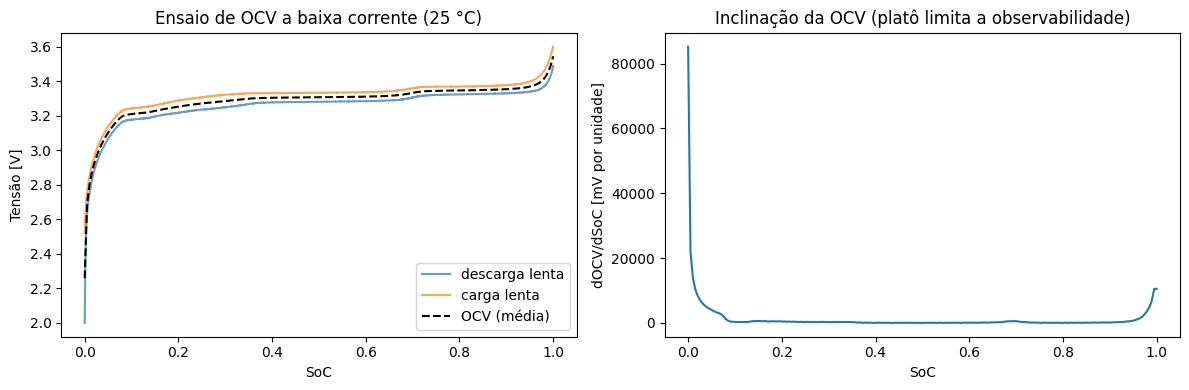

In [21]:
ocv_res = load_ocv_lowcurrent(ARQ_OCV, sheet=ABA_OCV, header_row=HEADER_OCV,
                              columns=COLUNAS_OCV, max_current_a=0.2)
ocv = ocv_res.table
display(ocv_res.runs.drop(columns=["ini", "fim"]))

CAP_NOMINAL_AH = 1.1       # informado pela página do CALCE para a célula A123
Q_REF = ocv_res.capacity_dis_ah
print(f"\nCapacidade medida na descarga lenta: {Q_REF:.4f} Ah | na carga lenta: "
      f"{ocv_res.capacity_chg_ah:.4f} Ah | nominal: {CAP_NOMINAL_AH} Ah")
if abs(Q_REF / CAP_NOMINAL_AH - 1) > 0.2:
    warnings.warn("Capacidade medida difere mais de 20% da nominal: confira o trecho escolhido, "
                  "a unidade da corrente e a célula.")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(ocv_res.soc_dis, ocv_res.v_dis, label="descarga lenta", alpha=0.7)
eixos[0].plot(ocv_res.soc_chg, ocv_res.v_chg, label="carga lenta", alpha=0.7)
eixos[0].plot(ocv.soc, ocv.ocv, "k--", label="OCV (média)")
eixos[0].set_xlabel("SoC"); eixos[0].set_ylabel("Tensão [V]"); eixos[0].legend()
eixos[0].set_title(f"Ensaio de OCV a baixa corrente ({TEMP_C} °C)")
eixos[1].plot(ocv.soc, 1e3 * ocv.slope(ocv.soc))
eixos[1].set_xlabel("SoC"); eixos[1].set_ylabel("dOCV/dSoC [mV por unidade]")
eixos[1].set_title("Inclinação da OCV (platô limita a observabilidade)")
plt.tight_layout(); plt.show()

## 3.4 Perfis dinâmicos e auditoria

A tabela abaixo é a **auditoria** que o plano exige antes de usar o dataset. Conferir:

* `dt_s` coerente com o esperado e `reamostrado` falso (ou justificado);
* `fator_sinal`: **+1** significa que a corrente do arquivo já era descarga positiva; **-1** que foi invertida. `correlacao_sinal` próxima de ±1 indica detecção confiável (o código avisa se for fraca);
* extremos de corrente compatíveis com uma célula de 1,1 Ah (se a corrente estiver em mA, os valores ficarão 1000 vezes maiores);
* extremos de tensão dentro da janela da célula (corte de carga 3,6 V e de descarga 2,0 V, segundo trabalho que usa estes dados).

Aba usada: Channel_1-005 | blocos encontrados: ['bloco_1']


,amostras,dt_s,duracao_h,fator_sinal,correlacao_sinal,reamostrado,i_max_A,i_min_A,v_min_V,v_max_V
bloco_1,37350,1.005071,10.427329,-1.0,0.999471,True,3.849713,-2.061054,2.000191,3.76623


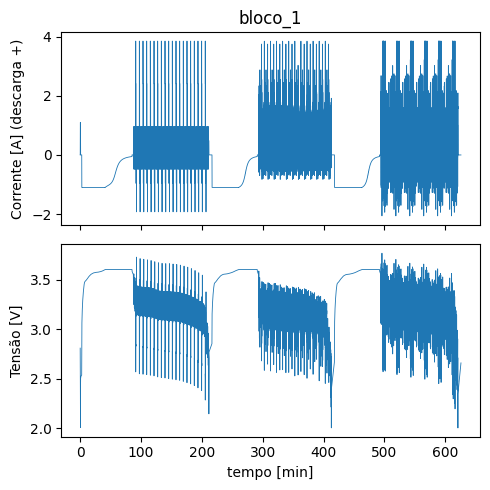

In [22]:
bruto = load_dynamic_profiles(ARQ_DIN, sheet=ABA_DIN, header_row=HEADER_DIN, columns=COLUNAS_DIN)
perfis = {nome: prepare_profile(nome, d["t"], d["i"], d["v"], d["temp"]) for nome, d in bruto.items()}
auditoria = pd.DataFrame({nome: p.info for nome, p in perfis.items()}).T
display(auditoria)

fig, eixos = plt.subplots(2, len(perfis), figsize=(5 * len(perfis), 5), sharex="col")
eixos = np.atleast_2d(eixos).reshape(2, -1)
for k, (nome, p) in enumerate(perfis.items()):
    eixos[0, k].plot(p.t / 60, p.i, lw=0.6); eixos[0, k].set_title(nome)
    eixos[1, k].plot(p.t / 60, p.v, lw=0.6); eixos[1, k].set_xlabel("tempo [min]")
eixos[0, 0].set_ylabel("Corrente [A] (descarga +)"); eixos[1, 0].set_ylabel("Tensão [V]")
plt.tight_layout(); plt.show()

## 3.5 SoC de referência

O SoC de referência vem da contagem de Coulomb com a capacidade medida (`Q_REF`) e um SoC inicial. **O SoC inicial dos perfis não está documentado na página do CALCE.** Como estimativa, o código inverte a tabela OCV com a tensão de repouso do início do ensaio, mas em LiFePO4 essa inversão é **pouco confiável no platô** (seção 1.3). Por isso:

1. Confiram o SoC inicial estimado contra o que sabem do protocolo (o ensaio começa de célula carregada? Qual tensão inicial?);
2. Se necessário, fixem o valor em `SOC0_MANUAL`;
3. O SoC final deve ficar dentro de [0, 1]. Se sair muito disso, algum de SoC inicial, capacidade ou sinal está errado.

Esta é uma **decisão de projeto** a registrar na D3 (definição de SoC de referência).

In [ ]:
SOC0_MANUAL = {}        # exemplo: {"DST": 1.0, "US06": 1.0, "FUDS": 1.0}

soc_ref, linhas = {}, []
for nome, p in perfis.items():
    v_rep, em_repouso = initial_rest_voltage(p.i, p.v)
    soc0_est = float(ocv.inverse(v_rep))
    soc0 = SOC0_MANUAL.get(nome, soc0_est)
    if not em_repouso:
        warnings.warn(f"{nome}: o ensaio não começa em repouso, então o SoC0 estimado pela OCV "
                      "é pouco confiável (queda ôhmica e platô). Defina SOC0_MANUAL.")
    soc_ref[nome] = integrate_soc(p.i, p.dt, soc0, Q_REF)
    linhas.append({"perfil": nome, "V_repouso_inicial [V]": v_rep, "início em repouso": em_repouso,
                   "SoC0 estimado": soc0_est, "SoC0 usado": soc0,
                   "SoC mín": soc_ref[nome].min(), "SoC máx": soc_ref[nome].max(),
                   "SoC final": soc_ref[nome][-1]})
display(pd.DataFrame(linhas).set_index("perfil"))
for nome, s in soc_ref.items():
    if s.min() < -0.02 or s.max() > 1.02:
        warnings.warn(f"{nome}: SoC de referência fora de [0, 1]. Revise SoC0, Q_REF e o sinal.")

fig, ax = plt.subplots(figsize=(8, 3.5))
for nome, s in soc_ref.items():
    ax.plot(perfis[nome].t / 60, s, label=nome)
ax.set_xlabel("tempo [min]"); ax.set_ylabel("SoC de referência"); ax.legend()
plt.tight_layout(); plt.show()

## 3.6 Identificação no DST

Identificam-se três modelos no **DST**: Rint com um $R_0$, Rint com $R_0^+$ e $R_0^-$ (Hu et al. 2012) e Thevenin 1RC. Confiram:

* `at_bounds` vazio (parâmetros colados em limites indicam problema; ajustem `BOUNDS` e justifiquem);
* $\tau_1$ e $R_1$ fisicamente plausíveis;
* `start_costs` parecidos entre inícios diferentes (muita dispersão indica mínimos locais).

Os limites abaixo são os padrão; **ajustem à célula e registrem**.

In [ ]:
NOME_ID = "DST"                       # perfil de identificação
NOMES_VAL = [n for n in perfis if n != NOME_ID]       # perfis de validação (FUDS, US06)
BOUNDS = None                         # exemplo: ([1e-3, 1e-3, 1.0], [0.3, 0.3, 1000.0])

p_id = perfis[NOME_ID]
aj_rint = fit_rint(p_id.i, p_id.v, soc_ref[NOME_ID], ocv)
aj_rint_dir = fit_rint(p_id.i, p_id.v, soc_ref[NOME_ID], ocv, directional=True)
aj_1rc = fit_thevenin_1rc(p_id.i, p_id.v, soc_ref[NOME_ID], ocv, p_id.dt, bounds=BOUNDS)

modelos = {
    "Rint": RintModel(aj_rint.params, ocv),
    "Rint R0±": RintModel(aj_rint_dir.params, ocv),
    "1RC": Thevenin1RC(aj_1rc.params, ocv),
}
print("Rint     :", aj_rint.params)
print("Rint R0± :", aj_rint_dir.params)
print("1RC      :", aj_1rc.params, f"| C1 = {aj_1rc.params.c1:.1f} F")
print("  parâmetros nos limites:", aj_1rc.at_bounds or "nenhum")
print("  incerteza aproximada (otimista):", aj_1rc.param_std)
print("  custos por início (multi-start):", np.round(aj_1rc.start_costs, 4))

## 3.7 Validação em perfis independentes e Gate G1

O modelo identificado no DST é avaliado, **sem reajuste**, no FUDS (validação indicada pelo CALCE) e no US06 (generalização extra). Métricas em **milivolts**.

**Gate G1 do plano:** *o 1RC atende ao erro requerido?* Se sim, o 2RC não é implementado como requisito. Duas observações:

* O erro "requerido" ainda precisa ser **definido por vocês na D3** (por exemplo, relacionado à inclinação da OCV e ao erro de SoC aceitável). Este notebook não o fixa.
* Olhem a **estrutura do resíduo** no tempo, não só o RMSE: resíduos sistemáticos após degraus de corrente sugerem dinâmica não modelada (candidato a 2RC); resíduos que dependem do SoC sugerem erro na curva OCV ou parâmetros variando com SoC.

In [ ]:
linhas, residuos = [], {}
for nome, p in perfis.items():
    for rotulo, modelo in modelos.items():
        r = evaluate_voltage(modelo, p.i, p.v, soc_ref[nome], p.dt)
        residuos[(nome, rotulo)] = r["residual"]
        linhas.append({"perfil": nome, "papel": "identificação" if nome == NOME_ID else "validação",
                       "modelo": rotulo, "MAE [mV]": 1e3 * r["mae"], "RMSE [mV]": 1e3 * r["rmse"],
                       "erro máx [mV]": 1e3 * r["max_abs"]})
tabela = pd.DataFrame(linhas)
display(tabela.round(2))

for nome in NOMES_VAL:
    r_rint = tabela[(tabela.perfil == nome) & (tabela.modelo == "Rint")]["RMSE [mV]"].iloc[0]
    r_1rc = tabela[(tabela.perfil == nome) & (tabela.modelo == "1RC")]["RMSE [mV]"].iloc[0]
    print(f"{nome}: RMSE Rint = {r_rint:.1f} mV | 1RC = {r_1rc:.1f} mV | redução = {100 * (1 - r_1rc / r_rint):.0f}%")

alvo = NOMES_VAL[0] if NOMES_VAL else NOME_ID
p = perfis[alvo]
fig, eixos = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
eixos[0].plot(p.t / 60, p.v, "k", lw=0.8, label="medida")
for rotulo in ("Rint", "1RC"):
    eixos[0].plot(p.t / 60, modelos[rotulo].voltage(p.i, soc_ref[alvo], p.dt), lw=0.7, label=rotulo)
eixos[0].set_ylabel("Tensão [V]"); eixos[0].legend(); eixos[0].set_title(f"Validação no {alvo}")
for rotulo in ("Rint", "1RC"):
    eixos[1].plot(p.t / 60, 1e3 * residuos[(alvo, rotulo)], lw=0.6, label=rotulo)
eixos[1].set_ylabel("resíduo [mV]"); eixos[1].legend()
eixos[2].plot(p.t / 60, p.i, lw=0.6); eixos[2].set_ylabel("corrente [A]"); eixos[2].set_xlabel("tempo [min]")
plt.tight_layout(); plt.show()

## 3.8 Salvando os parâmetros e os metadados

Gravem os parâmetros com os metadados completos. Eles são a entrada da etapa E4 (Coulomb Counting e EKF).

In [ ]:
PASTA_SAIDA = "/content/resultados"
os.makedirs(PASTA_SAIDA, exist_ok=True)
meta = {"celula": "A123 LiFePO4 (CALCE)", "temperatura_C": TEMP_C, "perfil_identificacao": NOME_ID,
        "arquivo_ocv": os.path.basename(ARQ_OCV), "arquivo_dinamico": os.path.basename(ARQ_DIN),
        "capacidade_ref_Ah": Q_REF, "dt_s": p_id.dt, "limites": None if BOUNDS is None else
        [list(map(float, b)) for b in BOUNDS], "convencao_corrente": "descarga positiva"}
save_params(os.path.join(PASTA_SAIDA, f"rint_{TEMP_C}C.json"), "rint", aj_rint.params, meta)
save_params(os.path.join(PASTA_SAIDA, f"thevenin_1rc_{TEMP_C}C.json"), "thevenin_1rc", aj_1rc.params, meta)
with open(os.path.join(PASTA_SAIDA, f"ocv_{TEMP_C}C.json"), "w") as f:
    json.dump(ocv.to_dict(), f)
tabela.to_csv(os.path.join(PASTA_SAIDA, f"metricas_tensao_{TEMP_C}C.csv"), index=False)
print("Arquivos salvos em", PASTA_SAIDA, ":", sorted(os.listdir(PASTA_SAIDA)))

## Próximos passos (E4)

* **Contagem de Coulomb** como baseline, com cenários de SoC inicial errado, bias de corrente e capacidade errada (já existe `integrate_soc`; falta o experimento de sensibilidade).
* **EKF**: estado $[\mathrm{SoC}, U_1]$, predição pelo modelo 1RC discreto, observação $\mathrm{OCV}(z) - R_0 i - U_1$ e Jacobiana com `ocv.slope()` (Plett 2004, Partes 1 e 3).
* Repetir para outras temperaturas e verificar se os parâmetros e a OCV mudam de forma relevante (pergunta de pesquisa sobre temperatura).